# 4th-Order Runge-Kutta: Example with 1 ODE

In [5]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

## Detph as a function of time in a draining tank

The following equation describe the time dependent solution of depth in a tank draining under atmospheric pressure through a drain line in the bottom of the tank:,

\begin{equation}
\frac{dh}{dt} = \frac{4}{\pi D^2}\left(Q_{in}-\frac{\pi d^2}{4}\sqrt{2gh}\right)
\end{equation}

Here $h=h(t)$ is the depth in the tank at any given time, $D$ is the diameter of the tank, $d$ is the diameter of the outlet, $Q_{in}$ is the volume flow rate of water entering the tank, and $g$ is the acceleration of gravity. Below this initial value problem is solved with 4th-order Runge-Kutta. 

In [6]:
# Let's copy over our domain setup and RK4 method from the previous notebook -------

# define the setup function
def setup(start,end,y0,stepsize):
    global t, y, N, dt # "global" will make arrays defined in the function available outside of the function
    dt = stepsize
    t = np.arange(start,end,dt)
    N = len(t)
    y = np.zeros(N)
    y[0] = y0
    return

# the 4th-order Runge-Kutta method
def RK4(t,y,f,dt):
    for i in range(0,N-1):
        K1 = f(t[i]       , y[i]          )
        K2 = f(t[i]+0.5*dt, y[i]+0.5*dt*K1)
        K3 = f(t[i]+0.5*dt, y[i]+0.5*dt*K2)
        K4 = f(t[i]+dt    , y[i]+dt*K3    )
        y[i+1] = y[i]+(dt/6)*(K1+2*K2+2*K3+K4)
#         if y[i+1] <= 0.001*y0: # get out of the loop if there is a zero-ish number for y coming up
#             tstop=i+1
#             print('numeric time to empty [min]=', around(t[tstop]/60,2))
#             break
    return y

# Now define the new functions -------

# define the function dy/dt = f(t,y)
def f(t,y):
    return 4/(np.pi*D**2)*(Qin-np.pi*d**2/4*np.sqrt(2*g*y))

# define the analytic solution
def yexact(t):
    return (-np.sqrt(g/2)*(d**2/D**2)*t+np.sqrt(y0))**2

analytic time to empty [min]= 9.32


/Users/kstrom/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:31: RuntimeWarning: invalid value encountered in sqrt


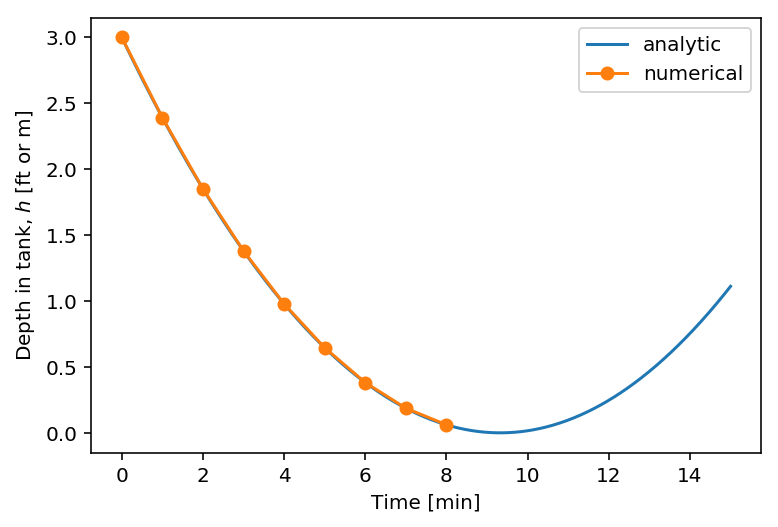

In [9]:
# --- User input ------------

# tank properties
g = 32.2 # acceleration of gravity
D = 3    # tank diamter in ft or m
d = 1/12 # drain diameter in ft or m
Qin = 0  # tank fill rate in cfs or cms
y0 = 3 # starting depth of water in the tank in ft or m
start = 0
end = 15*60 # run time in seconds
stepsize = 60 # calculation step size in seconds

# --- Calculations -----------

# Numeric
setup(start,end,y0,stepsize)
y2 = RK4(t,y,f,dt).copy()

# Exact
t_a = np.linspace(start,end,1000)
h_a = yexact(t_a)
t_empty = (D**2/d**2)*np.sqrt(2*y0/g)
print('analytic time to empty [min]=', np.around(t_empty/60,2))

# --- Plot the results ------------

fig, ax = plt.subplots()
# --- analytic solution
ax.plot(t_a/60,h_a, label='analytic')
# --- numeric solution
ax.plot(t/60,y2, '-o', label='numerical')
ax.set_xlabel('Time [min]')
ax.set_ylabel('Depth in tank, $h$ [ft or m]')
plt.legend(loc=1);

What is going on with the invalid value?

In [10]:
y2

array([3.        , 2.39100877, 1.85103419, 1.38007691, 0.97813823,
       0.64522122, 0.38133454, 0.18651094, 0.06096748,        nan,
              nan,        nan,        nan,        nan,        nan])

Try putting the code below into the RK4 loop under ```y[i+1]=```

```
        if y[i+1] <= 0.001*y0: # get out of the loop if there is a zero-ish number for y coming up
            tstop=i+1
            print('numeric time to empty [min]=', around(t[tstop]/60,2))
            break```